# Modeling Dataset Notebook
This notebook contains all the code required for building the modeling datasets for the three linear regression models. 

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Set file locations

In [2]:
# Project root
ROOT_DIR = Path.cwd().parent

# Raw data folder
RAW_DIR = ROOT_DIR / "raw_data"

# Processed output folder
OUTPUT_DIR = ROOT_DIR / "processed"
OUTPUT_DIR.mkdir(exist_ok=True)

# Source data files
transect_file = RAW_DIR / "california_transect_lookup.csv"
characteristics_file = RAW_DIR / "CoastSat_Calif_SeasonalCycleData.csv"
wave_file = RAW_DIR / "CDIP_monthly_P_Dir_for_Calif_CoastSat.csv"
roni_file = RAW_DIR / "RONI.csv"
shoreline_folder = (RAW_DIR / "shoreline_data" / "shoreline_data_run6" / "USA_CA")

## Load source data

In [3]:
# Load California transect lookup table
transects = pd.read_csv(transect_file)
transects

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id
0,usa_CA_0001-0000,32.541036,-117.090530,32.540497,-117.094751,0.055,usa_CA_0001
1,usa_CA_0001-0001,32.540186,-117.090404,32.539561,-117.094611,0.055,usa_CA_0001
2,usa_CA_0001-0002,32.539377,-117.090236,32.538600,-117.094412,0.055,usa_CA_0001
3,usa_CA_0001-0003,32.538545,-117.090025,32.537677,-117.094179,0.055,usa_CA_0001
4,usa_CA_0001-0004,32.537684,-117.089791,32.536788,-117.093937,0.055,usa_CA_0001
...,...,...,...,...,...,...,...
8142,usa_CA_0309-0008,42.025368,-124.162039,42.022566,-124.165107,0.035,usa_CA_0309
8143,usa_CA_0309-0009,42.025944,-124.163029,42.023094,-124.166013,0.035,usa_CA_0309
8144,usa_CA_0309-0010,42.026500,-124.164078,42.023577,-124.166925,0.035,usa_CA_0309
8145,usa_CA_0309-0011,42.027014,-124.165104,42.024064,-124.167898,0.035,usa_CA_0309


In [4]:
# Load transect characteristics data
characteristics = pd.read_csv(characteristics_file)
characteristics

,CoastSat_Section,CoastSat_Transect,Lat_AvShoreline_WGS84,Lon_AvShoreline_WGS84,ShoreOrientation_deg,Lat_Backbeach_WGS84,Lon_Backbeach_WGS84,BeachWidth_m,STL_SeasonalExcurs_m,STL_Tmin_mo,STL_Tmax_mo,STL_pval_tTest,fft_SeasonalExcurs_m,Periodogram_pval_annual,k_Means_Cluster
0,1,0,32.551559,-117.127297,261.5,32.551711,-117.126116,112.1,24.1,5.0,10.0,0.000001,19.7,0.000000,6
1,1,1,32.550675,-117.127063,260.1,32.550872,-117.125739,126.2,19.7,4.0,9.0,0.000000,19.2,0.000000,6
2,1,2,32.549796,-117.126797,257.7,32.550061,-117.125374,136.8,22.4,5.0,10.0,0.000000,21.4,0.000000,6
3,1,3,32.548927,-117.126521,256.2,32.549243,-117.125006,146.4,20.4,3.0,9.0,0.000000,20.7,0.000000,6
4,1,4,32.548061,-117.126245,255.8,32.548409,-117.124631,156.4,23.9,3.0,10.0,0.000000,22.6,0.000000,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7772,309,8,42.010329,-124.223719,220.1,42.010853,-124.223144,75.2,14.5,5.0,12.0,0.000000,10.1,0.000337,8
7773,309,9,42.010825,-124.224707,218.8,42.011369,-124.224137,76.7,9.9,5.0,12.0,0.000055,7.6,0.035759,8
7774,309,10,42.011345,-124.225657,216.8,42.011899,-124.225116,76.1,11.7,5.0,1.0,0.000108,8.4,0.001943,9
7775,309,11,42.011853,-124.226638,216.1,42.012465,-124.226058,83.2,17.0,5.0,2.0,0.000021,10.8,0.001371,9


In [5]:
# Load wave data
waves = pd.read_csv(wave_file)
waves

,CoastSat_Section,CoastSat_Transect,AvP_Jan,AvP_Feb,AvP_Mar,AvP_Apr,AvP_May,AvP_Jun,AvP_Jul,AvP_Aug,...,AvDir_Mar,AvDir_Apr,AvDir_May,AvDir_Jun,AvDir_Jul,AvDir_Aug,AvDir_Sep,AvDir_Oct,AvDir_Nov,AvDir_Dec
0,1,0,6.62,6.02,5.86,5.17,4.16,3.32,2.51,2.32,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
1,1,1,6.62,6.02,5.86,5.17,4.16,3.32,2.51,2.32,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
2,1,2,6.62,6.02,5.86,5.17,4.16,3.32,2.51,2.32,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
3,1,3,7.72,7.04,6.67,5.69,4.45,3.50,2.55,2.34,...,262.1,262.3,259.4,254.9,252.2,253.9,255.2,259.4,262.6,263.1
4,1,4,7.35,6.72,6.47,5.64,4.42,3.57,2.59,2.37,...,262.5,262.5,258.5,254.2,252.2,254.1,254.5,259.6,263.2,263.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7772,309,8,19.16,16.68,13.15,9.78,5.52,5.05,3.67,3.40,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7
7773,309,9,19.16,16.68,13.15,9.78,5.52,5.05,3.67,3.40,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7
7774,309,10,19.16,16.68,13.15,9.78,5.52,5.05,3.67,3.40,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7
7775,309,11,19.16,16.68,13.15,9.78,5.52,5.05,3.67,3.40,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7


In [6]:
# Load RONI data
roni = pd.read_csv(roni_file)
roni

,winter,RONI
0,1999-2000,-1.5
1,2000-2001,-0.8
2,2001-2002,-0.2
3,2002-2003,0.9
4,2003-2004,0.2
5,2004-2005,0.5
6,2005-2006,-0.9
7,2006-2007,0.6
8,2007-2008,-1.7
9,2008-2009,-1.0


## Add section and transect numbers to transect lookup table for merge

In [7]:
parts = transects["transect_id"].str.replace("usa_CA_", "").str.split("-")

transects["CoastSat_Section"] = parts.str[0].astype(int)
transects["CoastSat_Transect"] = parts.str[1].astype(int)
transects

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id,CoastSat_Section,CoastSat_Transect
0,usa_CA_0001-0000,32.541036,-117.090530,32.540497,-117.094751,0.055,usa_CA_0001,1,0
1,usa_CA_0001-0001,32.540186,-117.090404,32.539561,-117.094611,0.055,usa_CA_0001,1,1
2,usa_CA_0001-0002,32.539377,-117.090236,32.538600,-117.094412,0.055,usa_CA_0001,1,2
3,usa_CA_0001-0003,32.538545,-117.090025,32.537677,-117.094179,0.055,usa_CA_0001,1,3
4,usa_CA_0001-0004,32.537684,-117.089791,32.536788,-117.093937,0.055,usa_CA_0001,1,4
...,...,...,...,...,...,...,...,...,...
8142,usa_CA_0309-0008,42.025368,-124.162039,42.022566,-124.165107,0.035,usa_CA_0309,309,8
8143,usa_CA_0309-0009,42.025944,-124.163029,42.023094,-124.166013,0.035,usa_CA_0309,309,9
8144,usa_CA_0309-0010,42.026500,-124.164078,42.023577,-124.166925,0.035,usa_CA_0309,309,10
8145,usa_CA_0309-0011,42.027014,-124.165104,42.024064,-124.167898,0.035,usa_CA_0309,309,11


## Build master feature table for Southern California transects

In [8]:
# Merge transects data with characteristics data
features = transects.merge(characteristics, on=["CoastSat_Section", "CoastSat_Transect"])
features

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id,CoastSat_Section,CoastSat_Transect,Lat_AvShoreline_WGS84,...,Lat_Backbeach_WGS84,Lon_Backbeach_WGS84,BeachWidth_m,STL_SeasonalExcurs_m,STL_Tmin_mo,STL_Tmax_mo,STL_pval_tTest,fft_SeasonalExcurs_m,Periodogram_pval_annual,k_Means_Cluster
0,usa_CA_0001-0000,32.541036,-117.090530,32.540497,-117.094751,0.055,usa_CA_0001,1,0,32.551559,...,32.551711,-117.126116,112.1,24.1,5.0,10.0,0.000001,19.7,0.000000,6
1,usa_CA_0001-0001,32.540186,-117.090404,32.539561,-117.094611,0.055,usa_CA_0001,1,1,32.550675,...,32.550872,-117.125739,126.2,19.7,4.0,9.0,0.000000,19.2,0.000000,6
2,usa_CA_0001-0002,32.539377,-117.090236,32.538600,-117.094412,0.055,usa_CA_0001,1,2,32.549796,...,32.550061,-117.125374,136.8,22.4,5.0,10.0,0.000000,21.4,0.000000,6
3,usa_CA_0001-0003,32.538545,-117.090025,32.537677,-117.094179,0.055,usa_CA_0001,1,3,32.548927,...,32.549243,-117.125006,146.4,20.4,3.0,9.0,0.000000,20.7,0.000000,6
4,usa_CA_0001-0004,32.537684,-117.089791,32.536788,-117.093937,0.055,usa_CA_0001,1,4,32.548061,...,32.548409,-117.124631,156.4,23.9,3.0,10.0,0.000000,22.6,0.000000,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7772,usa_CA_0309-0008,42.025368,-124.162039,42.022566,-124.165107,0.035,usa_CA_0309,309,8,42.010329,...,42.010853,-124.223144,75.2,14.5,5.0,12.0,0.000000,10.1,0.000337,8
7773,usa_CA_0309-0009,42.025944,-124.163029,42.023094,-124.166013,0.035,usa_CA_0309,309,9,42.010825,...,42.011369,-124.224137,76.7,9.9,5.0,12.0,0.000055,7.6,0.035759,8
7774,usa_CA_0309-0010,42.026500,-124.164078,42.023577,-124.166925,0.035,usa_CA_0309,309,10,42.011345,...,42.011899,-124.225116,76.1,11.7,5.0,1.0,0.000108,8.4,0.001943,9
7775,usa_CA_0309-0011,42.027014,-124.165104,42.024064,-124.167898,0.035,usa_CA_0309,309,11,42.011853,...,42.012465,-124.226058,83.2,17.0,5.0,2.0,0.000021,10.8,0.001371,9


In [9]:
# Merge transects + characteristics with wave data
features = features.merge(waves, on=["CoastSat_Section", "CoastSat_Transect"])
features

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id,CoastSat_Section,CoastSat_Transect,Lat_AvShoreline_WGS84,...,AvDir_Mar,AvDir_Apr,AvDir_May,AvDir_Jun,AvDir_Jul,AvDir_Aug,AvDir_Sep,AvDir_Oct,AvDir_Nov,AvDir_Dec
0,usa_CA_0001-0000,32.541036,-117.090530,32.540497,-117.094751,0.055,usa_CA_0001,1,0,32.551559,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
1,usa_CA_0001-0001,32.540186,-117.090404,32.539561,-117.094611,0.055,usa_CA_0001,1,1,32.550675,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
2,usa_CA_0001-0002,32.539377,-117.090236,32.538600,-117.094412,0.055,usa_CA_0001,1,2,32.549796,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
3,usa_CA_0001-0003,32.538545,-117.090025,32.537677,-117.094179,0.055,usa_CA_0001,1,3,32.548927,...,262.1,262.3,259.4,254.9,252.2,253.9,255.2,259.4,262.6,263.1
4,usa_CA_0001-0004,32.537684,-117.089791,32.536788,-117.093937,0.055,usa_CA_0001,1,4,32.548061,...,262.5,262.5,258.5,254.2,252.2,254.1,254.5,259.6,263.2,263.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7772,usa_CA_0309-0008,42.025368,-124.162039,42.022566,-124.165107,0.035,usa_CA_0309,309,8,42.010329,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7
7773,usa_CA_0309-0009,42.025944,-124.163029,42.023094,-124.166013,0.035,usa_CA_0309,309,9,42.010825,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7
7774,usa_CA_0309-0010,42.026500,-124.164078,42.023577,-124.166925,0.035,usa_CA_0309,309,10,42.011345,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7
7775,usa_CA_0309-0011,42.027014,-124.165104,42.024064,-124.167898,0.035,usa_CA_0309,309,11,42.011853,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7


In [10]:
# Keep transects that are in Southern California (below 34.5 latitude)
features = features[features["Lat_AvShoreline_WGS84"] <= 34.5].copy()
features

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id,CoastSat_Section,CoastSat_Transect,Lat_AvShoreline_WGS84,...,AvDir_Mar,AvDir_Apr,AvDir_May,AvDir_Jun,AvDir_Jul,AvDir_Aug,AvDir_Sep,AvDir_Oct,AvDir_Nov,AvDir_Dec
0,usa_CA_0001-0000,32.541036,-117.090530,32.540497,-117.094751,0.055,usa_CA_0001,1,0,32.551559,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
1,usa_CA_0001-0001,32.540186,-117.090404,32.539561,-117.094611,0.055,usa_CA_0001,1,1,32.550675,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
2,usa_CA_0001-0002,32.539377,-117.090236,32.538600,-117.094412,0.055,usa_CA_0001,1,2,32.549796,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
3,usa_CA_0001-0003,32.538545,-117.090025,32.537677,-117.094179,0.055,usa_CA_0001,1,3,32.548927,...,262.1,262.3,259.4,254.9,252.2,253.9,255.2,259.4,262.6,263.1
4,usa_CA_0001-0004,32.537684,-117.089791,32.536788,-117.093937,0.055,usa_CA_0001,1,4,32.548061,...,262.5,262.5,258.5,254.2,252.2,254.1,254.5,259.6,263.2,263.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3215,usa_CA_0126-0013,34.446710,-120.407344,34.443481,-120.405526,0.095,usa_CA_0126,126,13,34.447918,...,183.6,179.7,176.7,176.2,175.6,175.5,176.2,178.6,183.4,185.8
3216,usa_CA_0126-0014,34.446069,-120.408573,34.443134,-120.406144,0.090,usa_CA_0126,126,14,34.447562,...,181.9,177.9,175.0,174.6,174.0,173.9,174.6,177.0,181.6,184.2
3217,usa_CA_0126-0015,34.445406,-120.409645,34.442713,-120.406838,0.085,usa_CA_0126,126,15,34.447085,...,181.9,177.9,175.0,174.6,174.0,173.9,174.6,177.0,181.6,184.2
3218,usa_CA_0126-0016,34.444537,-120.410691,34.442292,-120.407353,0.080,usa_CA_0126,126,16,34.446496,...,179.7,175.9,172.6,172.2,171.6,171.5,172.2,174.8,179.3,181.9


In [11]:
!pip install geopandas contextily

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\pakin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


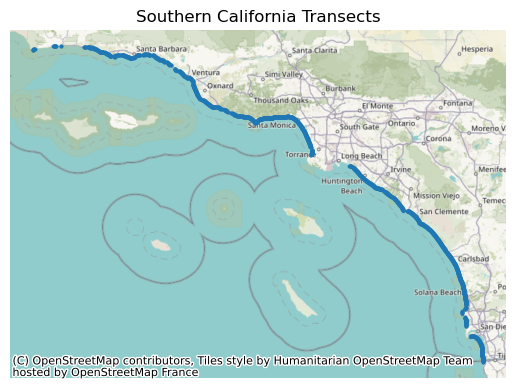

There are 3220 transects in Southern California.


In [12]:
# Plot Southern California transect locations
import geopandas as gpd
import contextily as ctx
import matplotlib.pyplot as plt

# Convert lat/lon columns to geographic points
map = gpd.GeoDataFrame(
    features,
    geometry=gpd.points_from_xy(
        features["Lon_AvShoreline_WGS84"],
        features["Lat_AvShoreline_WGS84"]
    ),
    crs="EPSG:4326"
)

# Convert to Web Mercator so it matches the basemap
map = map.to_crs(epsg=3857)

# Plot transects
map.plot(
    markersize=3,
    alpha=0.6,
)

ctx.add_basemap(plt.gca())

plt.title("Southern California Transects")
plt.axis("off")

plt.show()

socal_transects = features["transect_id"].nunique()
print(f"There are {socal_transects} transects in Southern California.")

In [13]:
# Saving master feature table
features.to_csv(OUTPUT_DIR / "master_transect_features.csv", index=False)

## Combine time-series data for transect shoreline positions

In [14]:
# Iterate through each site folder 
all_shorelines = []

for site_folder in shoreline_folder.iterdir():
    shoreline_file = site_folder / "time_series_tidally_corrected.csv"

    if shoreline_file.exists():
        df = pd.read_csv(shoreline_file)
        df = df.drop(columns=["Unnamed: 0"], errors="ignore")

        date_column = df.columns[0]

        df = df.melt(
            id_vars=date_column,
            var_name="transect_id",
            value_name="shoreline_position_m"
        )

        df = df.rename(columns={date_column: "date"})
        all_shorelines.append(df)

shoreline = pd.concat(all_shorelines, ignore_index=True)

shoreline["date"] = pd.to_datetime(shoreline["date"], errors="coerce")
shoreline["shoreline_position_m"] = pd.to_numeric(
    shoreline["shoreline_position_m"],
    errors="coerce"
)

print("Number of shoreline position observations in California:", len(shoreline))
shoreline.head(10)

Number of shoreline position observations in California: 6474041


,date,transect_id,shoreline_position_m
0,1984-03-23 17:50:13+00:00,usa_CA_0001-0000,261.790592
1,1984-05-06 17:49:52+00:00,usa_CA_0001-0000,260.733562
2,1984-06-07 17:50:43+00:00,usa_CA_0001-0000,265.368743
3,1984-06-23 17:50:58+00:00,usa_CA_0001-0000,270.314338
4,1984-08-26 17:52:34+00:00,usa_CA_0001-0000,274.015552
5,1984-12-16 17:52:39+00:00,usa_CA_0001-0000,NaN
6,1985-04-23 17:52:47+00:00,usa_CA_0001-0000,271.740527
7,1985-08-13 17:52:13+00:00,usa_CA_0001-0000,278.132489
8,1985-09-14 17:51:50+00:00,usa_CA_0001-0000,283.103936
9,1985-11-01 17:51:17+00:00,usa_CA_0001-0000,281.381639


In [15]:
# Keeping position observations for only Southern California transects
socal_transect_ids = features["transect_id"].unique()
socal_shoreline = shoreline[shoreline["transect_id"].isin(socal_transect_ids)].copy()

print("Number of shoreline position observations in Southern California:", len(socal_shoreline))
socal_shoreline.head(10)

Number of shoreline position observations in Southern California: 2768866


,date,transect_id,shoreline_position_m
0,1984-03-23 17:50:13+00:00,usa_CA_0001-0000,261.790592
1,1984-05-06 17:49:52+00:00,usa_CA_0001-0000,260.733562
2,1984-06-07 17:50:43+00:00,usa_CA_0001-0000,265.368743
3,1984-06-23 17:50:58+00:00,usa_CA_0001-0000,270.314338
4,1984-08-26 17:52:34+00:00,usa_CA_0001-0000,274.015552
5,1984-12-16 17:52:39+00:00,usa_CA_0001-0000,NaN
6,1985-04-23 17:52:47+00:00,usa_CA_0001-0000,271.740527
7,1985-08-13 17:52:13+00:00,usa_CA_0001-0000,278.132489
8,1985-09-14 17:51:50+00:00,usa_CA_0001-0000,283.103936
9,1985-11-01 17:51:17+00:00,usa_CA_0001-0000,281.381639


In [16]:
# Saving Southern California shoreline position time-series table
socal_shoreline.to_csv(OUTPUT_DIR / "shoreline_timeseries.csv", index=False)

## Isolate to winter months (December, January, February)

In [17]:
# Keep only December, January, and February for winter analysis
socal_shoreline = socal_shoreline[socal_shoreline["date"].dt.month.isin([12,1,2])].copy()

print("Number of shoreline position observations in Southern California during winter:", len(socal_shoreline))
socal_shoreline.head(10)

Number of shoreline position observations in Southern California during winter: 697270


,date,transect_id,shoreline_position_m
5,1984-12-16 17:52:39+00:00,usa_CA_0001-0000,NaN
11,1986-01-04 17:50:08+00:00,usa_CA_0001-0000,271.630447
12,1986-02-05 17:49:27+00:00,usa_CA_0001-0000,239.393558
13,1986-02-21 17:49:05+00:00,usa_CA_0001-0000,243.212041
21,1986-12-22 17:41:34+00:00,usa_CA_0001-0000,271.330001
22,1987-01-07 17:42:02+00:00,usa_CA_0001-0000,248.471875
23,1987-01-23 17:42:29+00:00,usa_CA_0001-0000,259.800606
24,1987-02-08 17:43:05+00:00,usa_CA_0001-0000,249.561851
60,1992-01-21 17:47:12+00:00,usa_CA_0001-0000,NaN
72,1992-12-22 17:43:56+00:00,usa_CA_0001-0000,254.535886


In [18]:
# Assign winter label by year based on date
def get_winter(date):

    if date.month == 12:
        return f"{date.year}-{date.year + 1}"

    else:
        return f"{date.year - 1}-{date.year}"

socal_shoreline["winter"] = socal_shoreline["date"].apply(get_winter)
socal_shoreline.head(10)

,date,transect_id,shoreline_position_m,winter
5,1984-12-16 17:52:39+00:00,usa_CA_0001-0000,NaN,1984-1985
11,1986-01-04 17:50:08+00:00,usa_CA_0001-0000,271.630447,1985-1986
12,1986-02-05 17:49:27+00:00,usa_CA_0001-0000,239.393558,1985-1986
13,1986-02-21 17:49:05+00:00,usa_CA_0001-0000,243.212041,1985-1986
21,1986-12-22 17:41:34+00:00,usa_CA_0001-0000,271.330001,1986-1987
22,1987-01-07 17:42:02+00:00,usa_CA_0001-0000,248.471875,1986-1987
23,1987-01-23 17:42:29+00:00,usa_CA_0001-0000,259.800606,1986-1987
24,1987-02-08 17:43:05+00:00,usa_CA_0001-0000,249.561851,1986-1987
60,1992-01-21 17:47:12+00:00,usa_CA_0001-0000,NaN,1991-1992
72,1992-12-22 17:43:56+00:00,usa_CA_0001-0000,254.535886,1992-1993


In [19]:
# Restrict timeframe to winters between 2000 and 2022 for CoastSat data
socal_shoreline = socal_shoreline[(socal_shoreline["winter"] >= "2000-2001") & (socal_shoreline["winter"] <= "2021-2022")].copy()
socal_shoreline

,date,transect_id,shoreline_position_m,winter
182,2000-12-04 18:12:52+00:00,usa_CA_0001-0000,278.651596,2000-2001
183,2000-12-28 18:02:15+00:00,usa_CA_0001-0000,257.144789,2000-2001
184,2001-01-13 18:02:23+00:00,usa_CA_0001-0000,258.978927,2000-2001
202,2001-12-07 18:11:06+00:00,usa_CA_0001-0000,253.024881,2001-2002
203,2002-01-08 18:11:17+00:00,usa_CA_0001-0000,231.272610,2001-2002
...,...,...,...,...
2909391,2021-02-26 18:40:42+00:00,usa_CA_0126-0017,176.327545,2020-2021
2909392,2021-02-27 17:48:46+00:00,usa_CA_0126-0017,NaN,2020-2021
2909423,2021-12-11 18:41:02+00:00,usa_CA_0126-0017,177.562180,2021-2022
2909424,2021-12-12 17:23:47+00:00,usa_CA_0126-0017,NaN,2021-2022


## Calculate winter shoreline change

In [20]:
# Remove missing shoreline positions and sort by date
shoreline_clean = (
    socal_shoreline
    .dropna(subset=["shoreline_position_m"])
    .sort_values(["transect_id", "winter", "date"])
)

# Summarize each transect for each winter
winter_change = (
    shoreline_clean
    .groupby(["transect_id", "winter"])
    .agg(
        first_date=("date", "first"),
        last_date=("date", "last"),
        first_position=("shoreline_position_m", "first"),
        last_position=("shoreline_position_m", "last"),
        observation_count=("shoreline_position_m", "count")
    )
    .reset_index()
)

# Calculate shoreline change for each winter
winter_change["shoreline_change_m"] = (winter_change["last_position"] - winter_change["first_position"])

# Calculate the number of days between first and last winter observation
winter_change["span_days"] = (winter_change["last_date"] - winter_change["first_date"]).dt.days

# Keep winter's observations only if there at least two over course of more than one month
winter_change = winter_change[(winter_change["observation_count"] >= 2) &(winter_change["span_days"] >= 45)].copy()
winter_change

,transect_id,winter,first_date,last_date,first_position,last_position,observation_count,shoreline_change_m,span_days
1,usa_CA_0001-0000,2001-2002,2001-12-07 18:11:06+00:00,2002-02-25 18:11:29+00:00,253.024881,242.448636,5,-10.576246,80
2,usa_CA_0001-0000,2002-2003,2002-12-02 17:54:05+00:00,2003-02-20 17:55:43+00:00,258.493276,237.103652,7,-21.389624,80
3,usa_CA_0001-0000,2003-2004,2003-12-21 18:01:13+00:00,2004-02-15 18:11:39+00:00,257.541207,245.183824,7,-12.357383,56
4,usa_CA_0001-0000,2004-2005,2004-12-15 18:11:45+00:00,2005-02-09 18:09:00+00:00,257.237016,248.957358,5,-8.279657,55
6,usa_CA_0001-0000,2006-2007,2006-12-13 18:17:12+00:00,2007-02-15 18:17:32+00:00,262.013544,242.402391,6,-19.611152,64
...,...,...,...,...,...,...,...,...,...
69492,usa_CA_0126-0017,2016-2017,2016-12-06 18:34:49+00:00,2017-02-24 18:34:24+00:00,176.410989,180.487469,11,4.076480,79
69493,usa_CA_0126-0017,2017-2018,2017-12-01 18:37:00+00:00,2018-02-27 18:34:13+00:00,173.781060,173.960550,13,0.179490,87
69494,usa_CA_0126-0017,2018-2019,2018-12-03 18:40:36+00:00,2019-02-22 18:28:06+00:00,172.764898,183.771425,12,11.006527,80
69495,usa_CA_0126-0017,2019-2020,2019-12-06 18:41:00+00:00,2020-02-25 18:12:34+00:00,148.836836,173.476293,13,24.639457,80


In [21]:
# Saving winter shoreline change table
winter_change.to_csv(OUTPUT_DIR / "winter_shoreline_change.csv", index=False)

## Create features for models

Features pertaining to directionality (shore orientation and wave direction) are converted into sine and cosine components to account for the circular nature of directional data in linear models.

In [22]:
# Convert shore orientation from characteristics 
orientation_rad = np.deg2rad(features["ShoreOrientation_deg"])

# Add shore orientation features in sin/cos
features["shore_orientation_sin"] = np.sin(orientation_rad)
features["shore_orientation_cos"] = np.cos(orientation_rad)
features.head(1)

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id,CoastSat_Section,CoastSat_Transect,Lat_AvShoreline_WGS84,...,AvDir_May,AvDir_Jun,AvDir_Jul,AvDir_Aug,AvDir_Sep,AvDir_Oct,AvDir_Nov,AvDir_Dec,shore_orientation_sin,shore_orientation_cos
0,usa_CA_0001-0000,32.541036,-117.09053,32.540497,-117.094751,0.055,usa_CA_0001,1,0,32.551559,...,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7,-0.989016,-0.147809


In [23]:
# Find average wave power for the winter
features["winter_wave_power"] = (features[["AvP_Dec", "AvP_Jan", "AvP_Feb"]].mean(axis=1))

# Convert wave direction
dec = np.deg2rad(features["AvDir_Dec"])
jan = np.deg2rad(features["AvDir_Jan"])
feb = np.deg2rad(features["AvDir_Feb"])

# Add average winter wave direction features in sin/cos
features["wave_dir_sin"] = (np.sin(dec) + np.sin(jan) + np.sin(feb))/3
features["wave_dir_cos"] = (np.cos(dec)+ np.cos(jan)+ np.cos(feb)) / 3
features.head(1)

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id,CoastSat_Section,CoastSat_Transect,Lat_AvShoreline_WGS84,...,AvDir_Aug,AvDir_Sep,AvDir_Oct,AvDir_Nov,AvDir_Dec,shore_orientation_sin,shore_orientation_cos,winter_wave_power,wave_dir_sin,wave_dir_cos
0,usa_CA_0001-0000,32.541036,-117.09053,32.540497,-117.094751,0.055,usa_CA_0001,1,0,32.551559,...,252.2,252.8,255.9,259.4,260.7,-0.989016,-0.147809,5.956667,-0.986087,-0.166194


In [24]:
# Feature selection
selected_features = features[["transect_id", "BeachWidth_m", "beach_slope", "shore_orientation_sin", "shore_orientation_cos", "winter_wave_power", "wave_dir_sin", "wave_dir_cos"]].copy()
selected_features

,transect_id,BeachWidth_m,beach_slope,shore_orientation_sin,shore_orientation_cos,winter_wave_power,wave_dir_sin,wave_dir_cos
0,usa_CA_0001-0000,112.1,0.055,-0.989016,-0.147809,5.956667,-0.986087,-0.166194
1,usa_CA_0001-0001,126.2,0.055,-0.985109,-0.171929,5.956667,-0.986087,-0.166194
2,usa_CA_0001-0002,136.8,0.055,-0.977046,-0.213030,5.956667,-0.986087,-0.166194
3,usa_CA_0001-0003,146.4,0.055,-0.971134,-0.238533,7.140000,-0.991338,-0.131099
4,usa_CA_0001-0004,156.4,0.055,-0.969445,-0.245307,6.770000,-0.992666,-0.120712
...,...,...,...,...,...,...,...,...
3215,usa_CA_0126-0013,63.6,0.095,0.447759,-0.894154,3.063333,-0.099898,-0.994988
3216,usa_CA_0126-0014,60.9,0.090,0.587785,-0.809017,3.066667,-0.072077,-0.997390
3217,usa_CA_0126-0015,63.9,0.085,0.674302,-0.738455,3.066667,-0.072077,-0.997390
3218,usa_CA_0126-0016,63.9,0.080,0.794415,-0.607376,3.006667,-0.031992,-0.999479


In [25]:
# Saving model features table
selected_features.to_csv(OUTPUT_DIR / "model_features.csv", index=False)

## Create modeling dataset

In [26]:
# Merge winter dataset with RONI values
model_data = winter_change.merge(
    selected_features,
    on="transect_id",
    how="inner"
)

model_data = model_data.merge(
    roni,
    on="winter",
    how="left"
)

model_data

,transect_id,winter,first_date,last_date,first_position,last_position,observation_count,shoreline_change_m,span_days,BeachWidth_m,beach_slope,shore_orientation_sin,shore_orientation_cos,winter_wave_power,wave_dir_sin,wave_dir_cos,RONI
0,usa_CA_0001-0000,2001-2002,2001-12-07 18:11:06+00:00,2002-02-25 18:11:29+00:00,253.024881,242.448636,5,-10.576246,80,112.1,0.055,-0.989016,-0.147809,5.956667,-0.986087,-0.166194,-0.2
1,usa_CA_0001-0000,2002-2003,2002-12-02 17:54:05+00:00,2003-02-20 17:55:43+00:00,258.493276,237.103652,7,-21.389624,80,112.1,0.055,-0.989016,-0.147809,5.956667,-0.986087,-0.166194,0.9
2,usa_CA_0001-0000,2003-2004,2003-12-21 18:01:13+00:00,2004-02-15 18:11:39+00:00,257.541207,245.183824,7,-12.357383,56,112.1,0.055,-0.989016,-0.147809,5.956667,-0.986087,-0.166194,0.2
3,usa_CA_0001-0000,2004-2005,2004-12-15 18:11:45+00:00,2005-02-09 18:09:00+00:00,257.237016,248.957358,5,-8.279657,55,112.1,0.055,-0.989016,-0.147809,5.956667,-0.986087,-0.166194,0.5
4,usa_CA_0001-0000,2006-2007,2006-12-13 18:17:12+00:00,2007-02-15 18:17:32+00:00,262.013544,242.402391,6,-19.611152,64,112.1,0.055,-0.989016,-0.147809,5.956667,-0.986087,-0.166194,0.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62318,usa_CA_0126-0017,2016-2017,2016-12-06 18:34:49+00:00,2017-02-24 18:34:24+00:00,176.410989,180.487469,11,4.076480,79,71.3,0.055,0.850811,-0.525472,3.006667,-0.031992,-0.999479,-0.6
62319,usa_CA_0126-0017,2017-2018,2017-12-01 18:37:00+00:00,2018-02-27 18:34:13+00:00,173.781060,173.960550,13,0.179490,87,71.3,0.055,0.850811,-0.525472,3.006667,-0.031992,-0.999479,-1.1
62320,usa_CA_0126-0017,2018-2019,2018-12-03 18:40:36+00:00,2019-02-22 18:28:06+00:00,172.764898,183.771425,12,11.006527,80,71.3,0.055,0.850811,-0.525472,3.006667,-0.031992,-0.999479,0.7
62321,usa_CA_0126-0017,2019-2020,2019-12-06 18:41:00+00:00,2020-02-25 18:12:34+00:00,148.836836,173.476293,13,24.639457,80,71.3,0.055,0.850811,-0.525472,3.006667,-0.031992,-0.999479,0.1


In [27]:
# Check table and values
print("Rows:", len(model_data))
print("Transects:", model_data["transect_id"].nunique())

print("\nMissing values:")
print(model_data.isna().sum())

Rows: 62323
Transects: 3220

Missing values:
transect_id                0
winter                     0
first_date                 0
last_date                  0
first_position             0
last_position              0
observation_count          0
shoreline_change_m         0
span_days                  0
BeachWidth_m               0
beach_slope              745
shore_orientation_sin      0
shore_orientation_cos      0
winter_wave_power          0
wave_dir_sin               0
wave_dir_cos               0
RONI                       0
dtype: int64


In [28]:
# Saving final modeling dataset
model_data.to_csv(OUTPUT_DIR / "final_modeling_dataset.csv", index=False)

In the modeling dataset, each row represents one Southern California transect during one winter season between 2000 and 2022. The dataset contains the winter shoreline change target (shoreline_change_m), beach morphology features (BeachWidth_m, beach_slope, shore_orientation_sin, shore_orientation_cos), characteristic winter wave features (winter_wave_power, wave_dir_sin, wave_dir_cos), and the corresponding winter RONI value. Different subsets of these predictors will be used for the three linear regression models.